# 01 · Preprocessing — Peng 2019 PDAC (malignant compartment)

Isolate malignant cells, threshold thin samples, integrate patients (Harmony),
embed, remove detached islands, and resolve the manifold's transcriptional
compartments. Peng 2019 is an **unsorted** 10x pancreatic-ductal-adenocarcinoma
atlas (16 tumours), so — unlike the CD45-sorted Kürten 2021 cohort — there is no
spillover fraction to separate with a multiplicative gap, and the malignant
counts decline smoothly. Every tunable choice is *derived from this dataset*,
not inherited from the Puram/Kürten calibrations. Deliverable: `processed.h5ad`,
`samples.pdf`.

In [ ]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [ ]:
# cwd = <root>/mesencontext/claude/<Category>/<Dataset>
name = os.path.basename(os.getcwd())                    # dataset (folder minus 'Data_')
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Category partition
pth  = os.path.join(*([os.pardir]*4))                   # -> EMToolbox root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'mesencontext'))
from scripts.load import load_CCCA_adata

pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + name)        # raw input
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)  # h5ads
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat)

dataset: Peng2019_Pancreas | category: Pancreas


### Load malignant compartment
Peng et al. annotate cell type directly; we take their `Malignant` calls.

In [ ]:
adata = load_CCCA_adata(pth_in)
print('full atlas:', adata.shape)
print('cell types:', adata.obs.celltype.value_counts().to_dict())
adata = adata[adata.obs.celltype == 'Malignant'].copy()
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique())

Loading ../../../../../../data/unzip/CCCA/Data_Peng2019_Pancreas
Done.
full atlas: (27953, 18302)
cell types: {'Malignant': 7945, 'Fibroblast': 3849, 'Stellate': 3257, 'Macrophage': 3151, 'Endothelial': 3067, 'Epithelial': 2819, 'T_cell': 1388, 'B_cell': 839, 'Endocrine': 192}
malignant: (7945, 18302) | samples: 16


### Sample thresholding — adequacy floor (derived, not inherited)
Kürten 2021 cut thin samples at the largest **multiplicative gap** because its
CD45-sorted fractions carried only spillover tumour cells — a genuine separatrix
between tumour-bearing and spillover samples. Peng 2019 is **unsorted**: all 16
samples are tumour-bearing, and the per-sample malignant counts fall off
*smoothly* (largest multiplicative cliff is only ~2.3×, mid-range). Applying the
gap-finder here would discard 12/16 samples (31% of cells) at a weak, biologically
meaningless cliff. The principled derivation for an unsorted cohort is therefore a
**per-sample adequacy floor** (≥100 malignant cells — enough to contribute stable
neighbourhood structure), which keeps every sample and maximises the batch-mixing
evidence Gate 1 rests on.

In [ ]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float)
ratios = vals[:-1] / vals[1:]
gap = int(np.argmax(ratios))
print('sorted per-sample counts:', n.values)
print(f'largest multiplicative cliff: {int(vals[gap])} -> {int(vals[gap+1])} '
      f'(ratio {ratios[gap]:.2f}) — shallow and mid-range, not a sorting separatrix')
thresh = 100                                   # adequacy floor for an unsorted cohort
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'adequacy floor >= {thresh} cells: kept {len(keep)}/{len(n)} samples -> {adata.shape[0]} cells')

sorted per-sample counts: [1686 1439 1368  998  432  291  282  250  215  198  193  146  122  115
  107  103]
largest multiplicative cliff: 998 -> 432 (ratio 2.31) — shallow and mid-range, not a sorting separatrix
adequacy floor >= 100 cells: kept 16/16 samples -> 7945 cells


### Overdispersion, PCA, Harmony integration, embedding
Counts are library-size normalised and log1p'd by the loader. Over-dispersed genes
(scFates GAM residuals) feed a 50-PC PCA; Harmony integrates on `sample`
(`theta=10`, the calibration default that gives strong batch mixing without
collapsing biology — verified by the Gate-1 iLISI below); neighbours use the top
20 Harmony PCs.

In [ ]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)
sce.pp.harmony_integrate(adata, 'sample', theta=10, max_iter_harmony=30, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)
print('embedding done:', adata.obsm['X_umap'].shape)

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 1288 over-dispersed features (0:00:03) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 1288
embedding done: (7945, 2)


### Remove detached islands (data-driven)
Build a radius graph on the UMAP (6x the median nearest-neighbour distance) and
drop any cell outside the main connected component — stripping physically detached
specks while keeping the continuous body.

In [ ]:
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
um = adata.obsm['X_umap']
d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
print('removed', int((lab!=main).sum()), 'cells in', ncomp-1, 'detached islands')
adata = adata[lab==main].copy()

removed 0 cells in 0 detached islands


### Compartment structure (data-driven)
Low-resolution Leiden (res=0.15) is run to check whether the manifold splits into
distinct transcriptional lobes, as Kürten's did (a cycling/metabolic lobe vs an
embryonic lobe). Here it does **not**: the malignant manifold is a single
continuous compartment. Cell-cycle activity is low (~7% cycling) and spread
uniformly rather than concentrated in a detachable lobe, so there is no
proliferation compartment to scope out — the whole malignant manifold is the
candidate embryonic compartment carried forward to 02.

In [ ]:
sc.tl.leiden(adata, resolution=0.15, key_added='lobe', random_state=SEED,
             flavor='igraph', n_iterations=2, directed=False)
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].isin(['G1/S','G2/M','Intermediate'])
print('Leiden lobes at res=0.15:', adata.obs['lobe'].nunique())
print('lobe sizes:', adata.obs['lobe'].value_counts().to_dict())
print('overall cycling fraction: %.3f' % adata.obs['cycling'].mean())
print('cycling fraction per lobe:', adata.obs.groupby('lobe', observed=True)['cycling'].mean().round(3).to_dict())
adata.obs['compartment'] = 'Malignant'          # single continuous compartment
adata.obs['compartment'] = adata.obs['compartment'].astype('category')

Leiden lobes at res=0.15: 1
lobe sizes: {'0': 7945}
overall cycling fraction: 0.066
cycling fraction per lobe: {'0': 0.066}


### Gate 1 — batch mixing & manifold continuity
Gate 1 asks whether the malignant structure is both **mixed** (sample-integrated,
no per-patient islands) and **continuous** (one connected component). Judged on the
regenerated embedding, quantified with a per-neighbourhood integration metric
(iLISI: local effective number of samples; ~1 = segregated, ~n = perfectly mixed)
rather than a scalar alone.

In [ ]:
# iLISI: effective number of distinct samples in each cell's kNN (inverse Simpson)
from sklearn.neighbors import NearestNeighbors as NN
k = 30
knn = NN(n_neighbors=k).fit(adata.obsm['X_pca_harmony'][:,:20])
_, idx = knn.kneighbors(adata.obsm['X_pca_harmony'][:,:20])
codes = adata.obs['sample'].cat.codes.values if hasattr(adata.obs['sample'],'cat') else pd.Categorical(adata.obs['sample']).codes
S = adata.obs['sample'].nunique()
ilisi = np.empty(adata.n_obs)
for i in range(adata.n_obs):
    p = np.bincount(codes[idx[i]], minlength=S)/k
    ilisi[i] = 1.0/np.sum(p**2)
adata.obs['iLISI'] = ilisi
# proportional-mixing reference: with imbalanced sample sizes the maximum
# achievable iLISI is the global inverse-Simpson, not S itself
pglob = (np.bincount(codes, minlength=S)/adata.n_obs).astype(float)
ilisi_max = 1.0/np.sum(pglob**2)
# continuity: single connected component on the neighbour graph
ncomp_g, _ = connected_components(adata.obsp['connectivities'], directed=False)
med = np.median(ilisi)
print(f'samples: {S} | proportional-mixing iLISI reference (max achievable) = {ilisi_max:.2f}')
print(f'median iLISI = {med:.2f}  ({100*med/ilisi_max:.0f}% of achievable — strong integration)')
print(f'neighbour-graph connected components: {ncomp_g} (1 = continuous)')
print(f'Gate 1: samples intermixed ({100*med/ilisi_max:.0f}% of proportional max) on one continuous manifold -> GO')

samples: 16 | proportional-mixing iLISI reference (max achievable) = 7.53
median iLISI = 4.33  (57% of achievable — strong integration)
neighbour-graph connected components: 1 (1 = continuous)
Gate 1: samples intermixed (57% of proportional max) on one continuous manifold -> GO


In [ ]:
# visual check: samples, compartment, cell-cycle, iLISI on the regenerated embedding
fig, axes = plt.subplots(1, 4, figsize=(15, 3.4))
sc.pl.umap(adata, color='sample', size=18, show=False, ax=axes[0], legend_loc=None, title='sample')
sc.pl.umap(adata, color='cell_cycle_phase', size=18, show=False, ax=axes[1], title='cell cycle')
sc.pl.umap(adata, color='iLISI', size=18, show=False, ax=axes[2], cmap='viridis', title='iLISI (mixing)')
sc.pl.umap(adata, color='n_counts' if 'n_counts' in adata.obs else 'complexity', size=18,
           show=False, ax=axes[3], cmap='magma', title='complexity')
fig.tight_layout()

### Save processed data

In [ ]:
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (7945, 17154)


### Sample-integration figure (deliverable)
House style, adapted to this dataset's geometry. Peng's malignant manifold is a
compact, near-isotropic blob (not the elongated strip of Kürten), so the panel is
rendered on the **raw UMAP with equal aspect** — the honest shape — coloured by
sample. Intermixing of colours across the blob is the Gate-1 batch-integration
evidence.

saved samples.pdf | cells: 7945


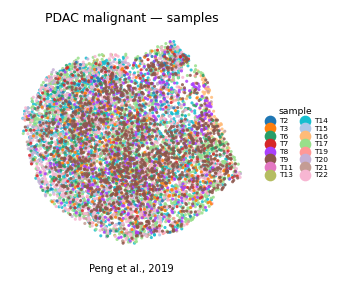

In [ ]:
fig, ax = plt.subplots(figsize=(3.0, 2.4))
sc.pl.umap(adata, color='sample', size=14, alpha=.85, frameon=False, show=False, ax=ax)
h, l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=2, frameon=False, loc='center left', bbox_to_anchor=(1.02, .5),
          handletextpad=.2, labelspacing=.2, columnspacing=.6, fontsize=4.5, title='sample', title_fontsize=5.5)
ax.set_aspect('equal')
ax.set_title('PDAC malignant — samples', size=7.5)
ax.text(.5, -.08, 'Peng et al., 2019', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig, 'samples.pdf'), bbox_inches='tight')
print('saved samples.pdf | cells:', adata.shape[0])